# Resultados por Run — Investigathon 2026
Datos extraídos de los archivos de análisis y logs de cada run.
Baseline = búsqueda aleatoria 10k muestras. SA = Simulated Annealing.

In [1]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np

plt.rcParams.update({
    'figure.dpi': 120,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.grid': True,
    'grid.alpha': 0.3,
})

RUNS = [1, 2, 3, 4, 5, 6]
RUN_LABELS = ['Run 1\nREINFORCE\n200ep', 'Run 2\nA2C\n500ep', 'Run 3\nA2C+fixes\n1000ep',
              'Run 4\nA2C+sparse\n2000ep', 'Run 5\nA2C+GAE\n200ep', 'Run 6\nA2C+GAE+fix\n1000ep']

# Métricas por run (score/paso)
mejor_score  = [-0.320, -0.110, -0.092, -0.163, -0.236, -0.155]
score_media  = [-0.580, -0.397, -0.369, -0.424, -0.435, -0.444]
conn_max     = [0.200,  0.300,  0.444,  0.689,  0.578,  0.578]
conn_media   = [0.100,  0.150,  0.280,  0.430,  0.347,  0.361]
r_media      = [0.998,  0.782,  0.841,  0.956,  0.900,  0.920]
tendencia    = [-0.0060, +0.0010, +0.0002, +0.000002, 0.0, 0.0]  # por episodio

# Referencias
BASELINE = +0.093   # búsqueda aleatoria 10k muestras
SA_SCORE = +0.168   # Simulated Annealing

# Paleta
COLOR_RUNS = plt.cm.viridis(np.linspace(0.15, 0.85, len(RUNS)))
COLOR_BASE = '#e05c2e'
COLOR_SA   = '#2eaae0'

print('Datos cargados.')

Datos cargados.


## 1. Mejor score por run

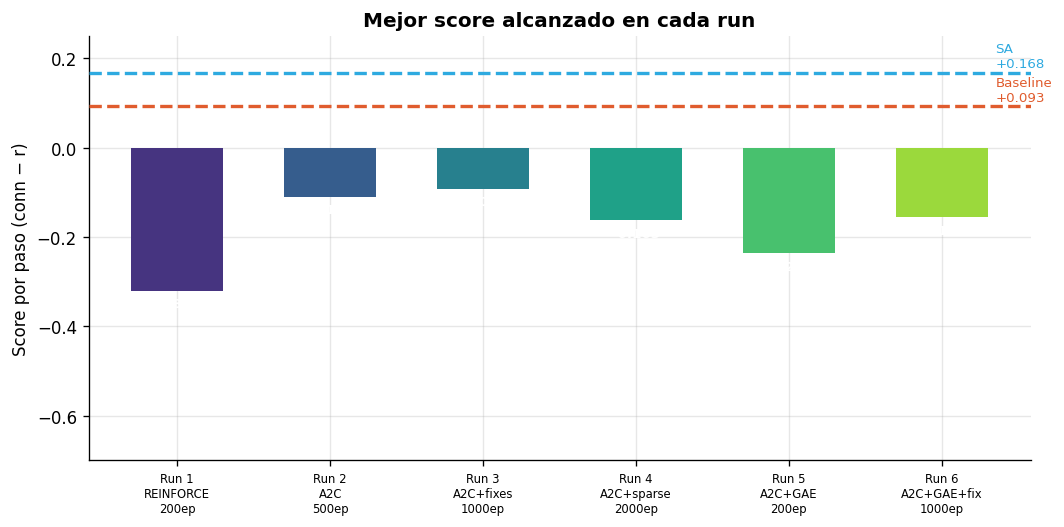

In [2]:
fig, ax = plt.subplots(figsize=(9, 4.5))

bars = ax.bar(RUNS, mejor_score, color=COLOR_RUNS, width=0.6, zorder=3)

ax.axhline(BASELINE, color=COLOR_BASE, lw=2, ls='--', zorder=4)
ax.axhline(SA_SCORE,  color=COLOR_SA,   lw=2, ls='--', zorder=4)
ax.text(6.35, BASELINE + 0.005, f'Baseline\n+{BASELINE:.3f}', color=COLOR_BASE, va='bottom', fontsize=8)
ax.text(6.35, SA_SCORE  + 0.005, f'SA\n+{SA_SCORE:.3f}',      color=COLOR_SA,   va='bottom', fontsize=8)

for bar, val in zip(bars, mejor_score):
    ax.text(bar.get_x() + bar.get_width()/2, val - 0.015,
            f'{val:.3f}', ha='center', va='top', fontsize=8, color='white', fontweight='bold')

ax.set_xticks(RUNS)
ax.set_xticklabels(RUN_LABELS, fontsize=7)
ax.set_ylabel('Score por paso (conn − r)')
ax.set_title('Mejor score alcanzado en cada run', fontweight='bold')
ax.set_ylim(-0.70, 0.25)
fig.tight_layout()
plt.show()

## 2. Score medio por run

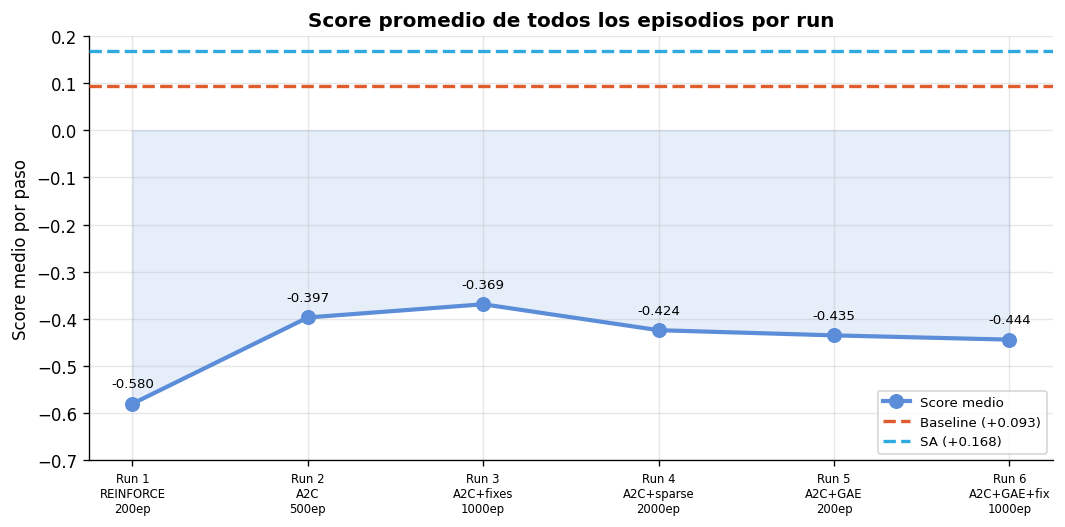

In [3]:
fig, ax = plt.subplots(figsize=(9, 4.5))

ax.plot(RUNS, score_media, 'o-', color='#5b8dd9', lw=2.5, ms=8, zorder=3, label='Score medio')
ax.fill_between(RUNS, score_media, alpha=0.15, color='#5b8dd9')

ax.axhline(BASELINE, color=COLOR_BASE, lw=2, ls='--', zorder=4, label=f'Baseline ({BASELINE:+.3f})')
ax.axhline(SA_SCORE,  color=COLOR_SA,   lw=2, ls='--', zorder=4, label=f'SA ({SA_SCORE:+.3f})')

for x, y in zip(RUNS, score_media):
    ax.annotate(f'{y:.3f}', (x, y), textcoords='offset points', xytext=(0, 10),
                ha='center', fontsize=8)

ax.set_xticks(RUNS)
ax.set_xticklabels(RUN_LABELS, fontsize=7)
ax.set_ylabel('Score medio por paso')
ax.set_title('Score promedio de todos los episodios por run', fontweight='bold')
ax.set_ylim(-0.70, 0.20)
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

## 3. Conectividad máxima y media por run

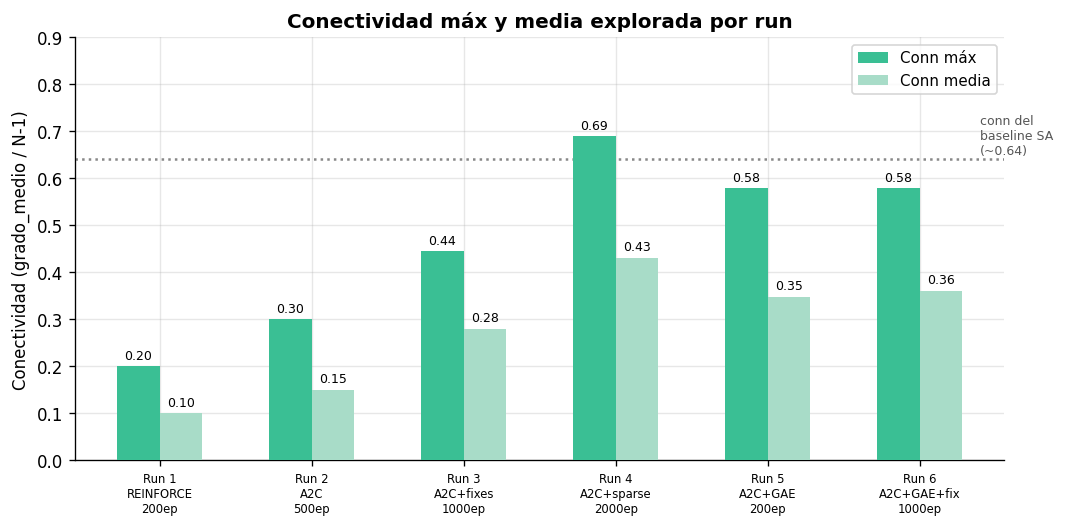

In [4]:
fig, ax = plt.subplots(figsize=(9, 4.5))

x = np.array(RUNS)
w = 0.28

b1 = ax.bar(x - w/2, conn_max,   width=w, label='Conn máx',   color='#3abf94', zorder=3)
b2 = ax.bar(x + w/2, conn_media, width=w, label='Conn media', color='#a8dcc8', zorder=3)

ax.axhline(0.64, color='#888', lw=1.5, ls=':', zorder=2)
ax.text(6.4, 0.645, 'conn del\nbaseline SA\n(~0.64)', fontsize=7.5, color='#555', va='bottom')

for bar, val in zip(list(b1) + list(b2), conn_max + conn_media):
    ax.text(bar.get_x() + bar.get_width()/2, val + 0.01,
            f'{val:.2f}', ha='center', va='bottom', fontsize=7.5)

ax.set_xticks(RUNS)
ax.set_xticklabels(RUN_LABELS, fontsize=7)
ax.set_ylabel('Conectividad (grado_medio / N-1)')
ax.set_title('Conectividad máx y media explorada por run', fontweight='bold')
ax.set_ylim(0, 0.90)
ax.legend(fontsize=9)
fig.tight_layout()
plt.show()

## 4. Parámetro r medio por run (sincronización)

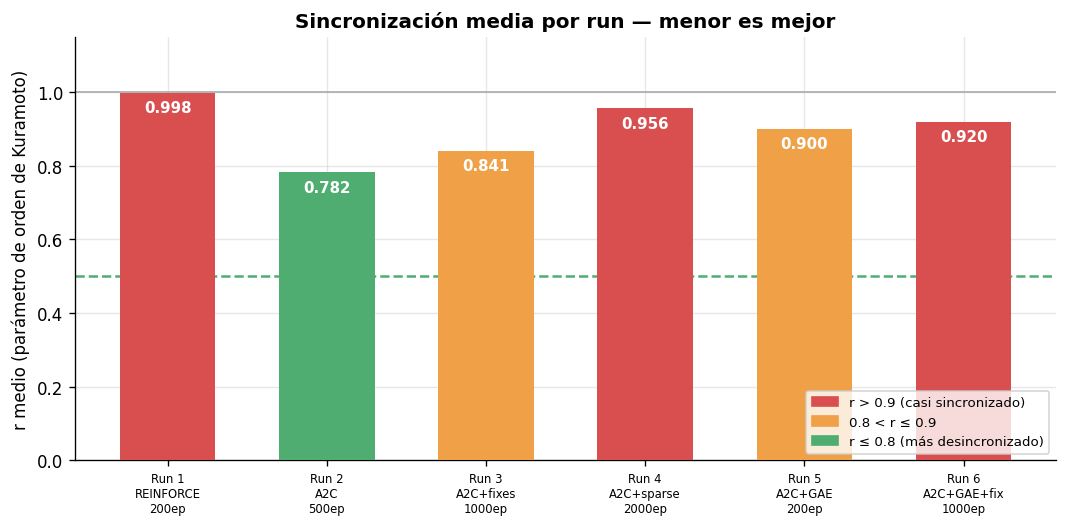

In [5]:
fig, ax = plt.subplots(figsize=(9, 4.5))

colors = ['#d94f4f' if r > 0.9 else '#f0a047' if r > 0.8 else '#4fad72' for r in r_media]
bars = ax.bar(RUNS, r_media, color=colors, width=0.6, zorder=3)

ax.axhline(1.0, color='#aaa', lw=1, ls='-')
ax.axhline(0.5, color='#4fad72', lw=1.5, ls='--', label='r=0.5 (umbral desincronización parcial)')

for bar, val in zip(bars, r_media):
    ax.text(bar.get_x() + bar.get_width()/2, val - 0.02,
            f'{val:.3f}', ha='center', va='top', fontsize=9, color='white', fontweight='bold')

red_p   = mpatches.Patch(color='#d94f4f', label='r > 0.9 (casi sincronizado)')
orange_p = mpatches.Patch(color='#f0a047', label='0.8 < r ≤ 0.9')
green_p  = mpatches.Patch(color='#4fad72', label='r ≤ 0.8 (más desincronizado)')

ax.set_xticks(RUNS)
ax.set_xticklabels(RUN_LABELS, fontsize=7)
ax.set_ylabel('r medio (parámetro de orden de Kuramoto)')
ax.set_title('Sincronización media por run — menor es mejor', fontweight='bold')
ax.set_ylim(0, 1.15)
ax.legend(handles=[red_p, orange_p, green_p], fontsize=8, loc='lower right')
fig.tight_layout()
plt.show()

## 5. Tendencia de aprendizaje (slope del score por episodio)

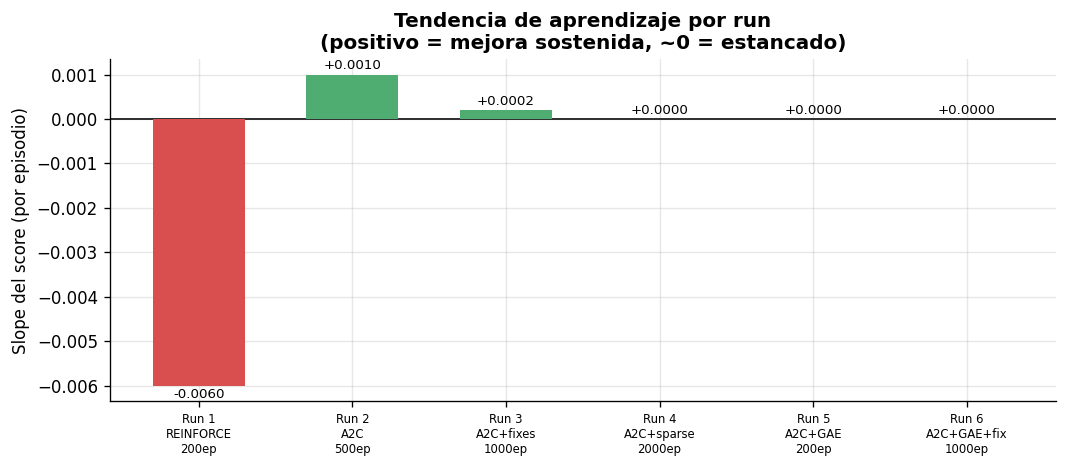

In [6]:
fig, ax = plt.subplots(figsize=(9, 4))

colors_t = ['#4fad72' if t > 0 else '#d94f4f' for t in tendencia]
bars = ax.bar(RUNS, tendencia, color=colors_t, width=0.6, zorder=3)
ax.axhline(0, color='#333', lw=1.2)

for bar, val in zip(bars, tendencia):
    offset = 0.00005 if val >= 0 else -0.00005
    va = 'bottom' if val >= 0 else 'top'
    ax.text(bar.get_x() + bar.get_width()/2, val + offset,
            f'{val:+.4f}', ha='center', va=va, fontsize=8)

ax.set_xticks(RUNS)
ax.set_xticklabels(RUN_LABELS, fontsize=7)
ax.set_ylabel('Slope del score (por episodio)')
ax.set_title('Tendencia de aprendizaje por run\n(positivo = mejora sostenida, ~0 = estancado)', fontweight='bold')
fig.tight_layout()
plt.show()

## 6. r vs Conectividad — mejores episodios de cada run
Muestra la tensión entre conectividad y sincronización. El objetivo es llegar a la esquina inferior derecha (alta conn, bajo r).

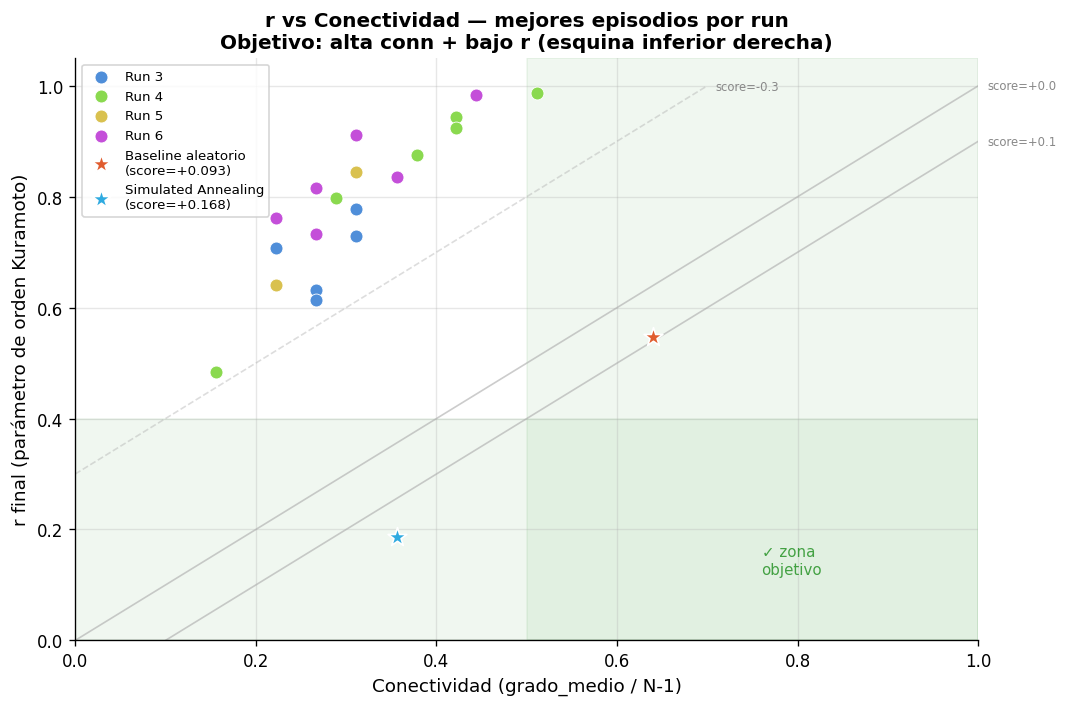

In [7]:
# Datos: mejores episodios ('nuevo mejor') de cada run
# Formato: (conn, r, score, run_id)
mejores_eps = [
    # Run 3
    (0.311, 0.777, -0.466, 3), (0.222, 0.707, -0.485, 3),
    (0.267, 0.631, -0.364, 3), (0.311, 0.729, -0.418, 3),
    (0.267, 0.614, -0.347, 3),  # ← mejor R3
    # Run 4
    (0.289, 0.798, -0.367, 4), (0.422, 0.944, -0.318, 4),
    (0.156, 0.483, -0.281, 4), (0.511, 0.986, -0.272, 4),
    (0.422, 0.923, -0.211, 4), (0.378, 0.875, -0.163, 4),  # ← mejor R4
    # Run 5
    (0.311, 0.844, -0.269, 5), (0.222, 0.641, -0.236, 5),  # ← mejor R5
    # Run 6
    (0.444, 0.983, -0.476, 6), (0.311, 0.911, -0.374, 6),
    (0.222, 0.761, -0.338, 6), (0.267, 0.816, -0.292, 6),
    (0.267, 0.732, -0.178, 6), (0.356, 0.836, -0.155, 6),  # ← mejor R6
]

# Baseline y SA como puntos de referencia (estimados)
# Baseline aleatorio: conn≈0.64, score=+0.093 → r = conn - score = 0.64 - 0.093 = 0.547
# SA: conn=0.356, r=0.187, score=+0.168

conn_ep = [x[0] for x in mejores_eps]
r_ep    = [x[1] for x in mejores_eps]
sc_ep   = [x[2] for x in mejores_eps]
run_ep  = [x[3] for x in mejores_eps]

run_colors = {3: '#4f8ed9', 4: '#8ad94f', 5: '#d9c14f', 6: '#c44fd9'}

fig, ax = plt.subplots(figsize=(9, 6))

# Región objetivo
ax.axvspan(0.5, 1.0, alpha=0.06, color='green')
ax.axhspan(0.0, 0.4, alpha=0.06, color='green')
ax.text(0.76, 0.12, '✓ zona\nobjetivo', color='green', fontsize=9, alpha=0.7)

for run_id in [3, 4, 5, 6]:
    xs = [x[0] for x in mejores_eps if x[3] == run_id]
    ys = [x[1] for x in mejores_eps if x[3] == run_id]
    ax.scatter(xs, ys, color=run_colors[run_id], s=60, zorder=4,
               label=f'Run {run_id}', edgecolors='white', lw=0.5)

# Baseline y SA
ax.scatter([0.64], [0.547], color=COLOR_BASE, s=140, marker='*', zorder=5,
           label=f'Baseline aleatorio\n(score=+0.093)', edgecolors='white')
ax.scatter([0.356], [0.187], color=COLOR_SA, s=140, marker='*', zorder=5,
           label=f'Simulated Annealing\n(score=+0.168)', edgecolors='white')

# Líneas iso-score (conn - r = cte)
c_vals = np.linspace(0, 1, 200)
for iso, ls, alpha in [(-0.3, '--', 0.4), (0.0, '-', 0.6), (+0.1, '-', 0.6)]:
    r_iso = c_vals - iso
    mask  = (r_iso >= 0) & (r_iso <= 1)
    ax.plot(c_vals[mask], r_iso[mask], ls=ls, lw=1, color='#aaa', alpha=alpha)
    ax.text(c_vals[mask][-1] + 0.01, r_iso[mask][-1],
            f'score={iso:+.1f}', fontsize=7, color='#888', va='center')

ax.set_xlabel('Conectividad (grado_medio / N-1)', fontsize=11)
ax.set_ylabel('r final (parámetro de orden Kuramoto)', fontsize=11)
ax.set_title('r vs Conectividad — mejores episodios por run\n'
             'Objetivo: alta conn + bajo r (esquina inferior derecha)', fontweight='bold')
ax.set_xlim(0, 1.0)
ax.set_ylim(0, 1.05)
ax.legend(fontsize=8, loc='upper left')
fig.tight_layout()
plt.show()

## 7. Resumen comparativo — tabla numérica

In [8]:
import pandas as pd

df = pd.DataFrame({
    'Run':          ['Run 1', 'Run 2', 'Run 3', 'Run 4', 'Run 5', 'Run 6', 'Baseline', 'SA'],
    'Algoritmo':    ['REINFORCE','A2C','A2C+fixes','A2C+sparse','A2C+GAE','A2C+GAE+fix','Aleatorio','Sim.Anneal.'],
    'Episodios':    [200, 500, 1000, 2000, 200, 1000, '10k muestras', '—'],
    'Mejor score':  [-0.320, -0.110, -0.092, -0.163, -0.236, -0.155, +0.093, +0.168],
    'Score medio':  [-0.580, -0.397, -0.369, -0.424, -0.435, -0.444, -0.392, '—'],
    'Conn máx':     [0.20,  0.30,  0.44,  0.69,  0.578, 0.578, 0.64, 0.356],
    'Conn media':   [0.10,  0.15,  0.28,  0.43,  0.347, 0.361, '—', '—'],
    'r medio':      [0.998, 0.782, 0.841, 0.956, 0.900, 0.920, '—', 0.187],
})

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 120)
df

,Run,Algoritmo,Episodios,Mejor score,Score medio,Conn máx,Conn media,r medio
0,Run 1,REINFORCE,200,-0.320,-0.58,0.200,0.1,0.998
1,Run 2,A2C,500,-0.110,-0.397,0.300,0.15,0.782
2,Run 3,A2C+fixes,1000,-0.092,-0.369,0.440,0.28,0.841
3,Run 4,A2C+sparse,2000,-0.163,-0.424,0.690,0.43,0.956
4,Run 5,A2C+GAE,200,-0.236,-0.435,0.578,0.347,0.9
5,Run 6,A2C+GAE+fix,1000,-0.155,-0.444,0.578,0.361,0.92
6,Baseline,Aleatorio,10k muestras,0.093,-0.392,0.640,—,—
7,SA,Sim.Anneal.,—,0.168,—,0.356,—,0.187


## 8. Animación — Run 8: cómo el agente construye el grafo paso a paso

El agente arranca desde el **grafo circulante conocido** (N=22, l=7, 154 aristas) y añade aristas una por una en modo greedy (sin epsilon).  
La animación muestra el grafo en cada paso, la arista recién agregada destacada en naranja, y la evolución del score y la sincronización (r) a lo largo del episodio.

In [ ]:
import json
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.gridspec as gridspec
from matplotlib.animation import FuncAnimation
from matplotlib.lines import Line2D
from IPython.display import HTML

# ── Cargar datos de fotos ───────────────────────────────────────────────────

FOTOS_PATH = "../checkpoints/run8/fotos_episodio.json"

with open(FOTOS_PATH, "r", encoding="utf-8") as f:
    data = json.load(f)

N      = data["N"]
pasos  = data["pasos"]
W_base = np.array(data["W_base"])

# Posiciones en círculo (nodo i en ángulo 2πi/N)
angles   = 2 * np.pi * np.arange(N) / N
pos_x    = np.cos(angles)
pos_y    = np.sin(angles)

# Aristas del grafo base (siempre visibles)
base_edges = set()
for i in range(N):
    for j in range(i + 1, N):
        if W_base[i, j] > 0.5:
            base_edges.add((i, j))

# Secuencia de aristas añadidas
aristas_agregadas = []
for p in pasos:
    if p["arista_agregada"] is not None:
        aristas_agregadas.append(tuple(p["arista_agregada"]))
    else:
        aristas_agregadas.append(None)

scores     = [p["score"]        for p in pasos]
conns      = [p["conectividad"] for p in pasos]
r_vals     = [p["r_final"]      for p in pasos]
n_aristas  = [p["n_aristas"]    for p in pasos]

# ── Paleta ──────────────────────────────────────────────────────────────────

COLOR_BASE    = "#4a90d9"    # aristas del grafo conocido
COLOR_NEW     = "#ff7f2a"    # arista recién agregada
COLOR_OLD_ADD = "#a8d4f5"    # aristas añadidas en pasos anteriores
COLOR_NODE    = "#1a3a5c"    # nodos
COLOR_SCORE   = "#3abf94"    # línea de score
COLOR_R       = "#e05c2e"    # línea de r
COLOR_CONN    = "#9b59b6"    # línea de conn
BG            = "#f7f9fc"

# ── Figura ──────────────────────────────────────────────────────────────────

fig = plt.figure(figsize=(14, 6.5), facecolor=BG)
fig.subplots_adjust(left=0.04, right=0.98, top=0.92, bottom=0.1, wspace=0.35)

gs = gridspec.GridSpec(2, 2, figure=fig, height_ratios=[1, 1],
                       left=0.04, right=0.98, top=0.91, bottom=0.10,
                       wspace=0.38, hspace=0.5)

ax_grafo = fig.add_subplot(gs[:, 0])   # grafo (ocupa toda la altura izquierda)
ax_score = fig.add_subplot(gs[0, 1])   # score
ax_r     = fig.add_subplot(gs[1, 1])   # r y conn

for ax in [ax_grafo, ax_score, ax_r]:
    ax.set_facecolor(BG)
    for sp in ax.spines.values():
        sp.set_visible(False)

ax_grafo.set_aspect('equal')
ax_grafo.set_xlim(-1.35, 1.35)
ax_grafo.set_ylim(-1.35, 1.35)
ax_grafo.axis('off')

# Paneles de métricas
for ax in [ax_score, ax_r]:
    ax.grid(True, alpha=0.2, lw=0.7)
    ax.tick_params(labelsize=8)

ax_score.set_xlim(0, len(pasos) - 1)
ax_score.set_ylim(min(scores) - 0.05, max(scores) + 0.05)
ax_score.set_xlabel("Paso", fontsize=8)
ax_score.set_ylabel("Score (conn − r)", fontsize=8)
ax_score.set_title("Score por paso", fontsize=9, fontweight='bold')
ax_score.axhline(0.093, color='#e05c2e', ls='--', lw=1, alpha=0.7, label='Baseline (+0.093)')
ax_score.axhline(0.168, color='#2eaae0', ls='--', lw=1, alpha=0.7, label='SA (+0.168)')
ax_score.legend(fontsize=7, framealpha=0.7, loc='upper right')

ax_r.set_xlim(0, len(pasos) - 1)
ax_r.set_ylim(-0.05, 1.05)
ax_r.set_xlabel("Paso", fontsize=8)
ax_r.set_ylabel("Valor", fontsize=8)
ax_r.set_title("Sincronización (r) y Conectividad", fontsize=9, fontweight='bold')

leyenda_r = [
    Line2D([0], [0], color=COLOR_R,    lw=1.8, label='r (sincronización)'),
    Line2D([0], [0], color=COLOR_CONN, lw=1.8, label='conectividad'),
]
ax_r.legend(handles=leyenda_r, fontsize=7, framealpha=0.7, loc='center right')

# ── Título ───────────────────────────────────────────────────────────────────

titulo = fig.suptitle("Run 8 — Paso 0/40 · Grafo conocido (154 aristas)",
                      fontsize=11, fontweight='bold', color='#1a3a5c', y=0.97)

# ── Elementos del grafo ──────────────────────────────────────────────────────

# Dibujar nodos (estáticos)
ax_grafo.scatter(pos_x, pos_y, s=120, c=COLOR_NODE, zorder=5,
                 edgecolors='white', linewidths=1.2)
# Etiquetas de nodo
for i in range(N):
    ax_grafo.text(pos_x[i] * 1.18, pos_y[i] * 1.18, str(i),
                  ha='center', va='center', fontsize=6.5,
                  color='#2c4e7a', fontweight='bold')

# Líneas de aristas (base): dibujamos todas de golpe como fondo
for (i, j) in base_edges:
    ax_grafo.plot([pos_x[i], pos_x[j]], [pos_y[i], pos_y[j]],
                  color=COLOR_BASE, lw=0.8, alpha=0.55, zorder=1)

# Contenedores para aristas añadidas durante el episodio
added_lines  = []   # Line2D de aristas añadidas (historial)
new_line,    = ax_grafo.plot([], [], color=COLOR_NEW, lw=2.5, alpha=1.0, zorder=4)

# Líneas de las métricas (se construyen incrementalmente)
score_line, = ax_score.plot([], [], color=COLOR_SCORE, lw=2, zorder=3)
r_line,     = ax_r.plot([], [], color=COLOR_R,    lw=1.8, zorder=3)
conn_line,  = ax_r.plot([], [], color=COLOR_CONN, lw=1.8, zorder=3, ls='--')

# Marcador del punto actual en score
score_dot,  = ax_score.plot([], [], 'o', color=COLOR_SCORE, ms=6, zorder=4)

# Leyenda del grafo
leg_base = mpatches.Patch(color=COLOR_BASE,    label=f'Aristas grafo conocido ({len(base_edges)})')
leg_add  = mpatches.Patch(color=COLOR_OLD_ADD, label='Aristas añadidas (anteriores)')
leg_new  = mpatches.Patch(color=COLOR_NEW,     label='Arista añadida (este paso)')
ax_grafo.legend(handles=[leg_base, leg_add, leg_new],
                fontsize=7, loc='lower center', framealpha=0.85,
                bbox_to_anchor=(0.5, -0.04))

# ── Animación ───────────────────────────────────────────────────────────────

def init():
    new_line.set_data([], [])
    score_line.set_data([], [])
    r_line.set_data([], [])
    conn_line.set_data([], [])
    score_dot.set_data([], [])
    for ln in added_lines:
        ln.remove()
    added_lines.clear()
    return [new_line, score_line, r_line, conn_line, score_dot]


def update(frame):
    paso  = frame

    # ── Grafo ──
    # Arista recién añadida
    arista = aristas_agregadas[paso]
    if arista is not None:
        i, j = arista
        new_line.set_data([pos_x[i], pos_x[j]], [pos_y[i], pos_y[j]])
    else:
        new_line.set_data([], [])

    # Historial de aristas añadidas (hasta el paso anterior)
    # Limpiamos y volvemos a dibujar solo los históricos
    for ln in added_lines:
        ln.remove()
    added_lines.clear()

    for k in range(1, paso):   # pasos anteriores (no el actual)
        ar = aristas_agregadas[k]
        if ar is not None:
            ii, jj = ar
            ln, = ax_grafo.plot([pos_x[ii], pos_x[jj]], [pos_y[ii], pos_y[jj]],
                                color=COLOR_OLD_ADD, lw=1.4, alpha=0.8, zorder=2)
            added_lines.append(ln)

    # ── Métricas ──
    xs = list(range(paso + 1))
    score_line.set_data(xs, scores[:paso + 1])
    r_line.set_data(xs,     r_vals[:paso + 1])
    conn_line.set_data(xs,  conns[:paso + 1])
    score_dot.set_data([paso], [scores[paso]])

    # ── Título ──
    sc  = scores[paso]
    rv  = r_vals[paso]
    cv  = conns[paso]
    na  = n_aristas[paso]
    if arista is not None:
        i, j = arista
        titulo.set_text(f"Run 8 — Paso {paso}/40  ·  Añadida ({i},{j})  ·  "
                        f"Score={sc:+.3f}  ·  r={rv:.3f}  ·  conn={cv:.3f}  ·  {na} aristas")
    else:
        titulo.set_text(f"Run 8 — Paso 0/40  ·  Grafo conocido  ·  "
                        f"Score={sc:+.3f}  ·  r={rv:.3f}  ·  conn={cv:.3f}  ·  {na} aristas")

    return [new_line, score_line, r_line, conn_line, score_dot, titulo] + added_lines


anim = FuncAnimation(
    fig, update, frames=len(pasos),
    init_func=init,
    interval=600,   # ms por frame — ajustar a gusto
    blit=False,
)

plt.close(fig)   # no mostrar figura estática

# Mostrar como HTML interactivo (requiere ffmpeg o pillow; usa jshtml como fallback)
try:
    html_anim = anim.to_jshtml(fps=2, default_mode='loop')
    display(HTML(html_anim))
except Exception as e:
    print(f"Error al generar HTML: {e}")
    print("Guardando como GIF en su lugar...")
    anim.save("../checkpoints/run8/animacion_episodio.gif", writer="pillow", fps=2)
    from IPython.display import Image
    display(Image("../checkpoints/run8/animacion_episodio.gif"))